# Estimating π with a Monte Carlo Simulation

## Problem and objective
This project estimates π by placing random points inside a square. We count how many points land inside a quarter circle, then use that share to estimate π. We will see how the number of points affects the estimate and how results differ between repeated runs.

## Mathematical idea
The square goes from 0 to 1 on both axes, and it contains a quarter circle with radius 1. The square has area 1 and the quarter circle has area π/4. If every location in the square is equally likely, a point has probability π/4 of landing inside the quarter circle.

For $N$ points, let $K$ be the number inside the quarter circle. Then

$$\hat{\pi}=4\frac{K}{N}.$$

## Questions
- Does the error usually get smaller when we use more points?
- How different are the results from one run to another?
- Do the averages and standard deviations match what we expect from the Law of Large Numbers?

## Assumptions
The points are chosen independently, meaning one point does not affect another, and every location in the square is equally likely. A larger sample often gives a closer estimate, but any single run can still be off.

In [19]:
import matplotlib.pyplot as plt
import numpy as np

## The simulation function

The function below makes random points in the unit square. It checks whether each point is inside the quarter circle using $x^2+y^2 \leq 1$. The estimate is four times the share of points inside.

Give the function a seed to repeat the same run in the same NumPy version and environment. Without a seed, it uses a new random sample. NumPy notes that exact random results can differ between versions ([Generator documentation](https://numpy.org/doc/stable/reference/random/generator.html)).

The functions in this notebook expect point counts and run counts to be positive whole numbers.

In [20]:
def estimate_pi(n_points, seed=None):
    rng = np.random.default_rng(seed)
    points = rng.random((n_points, 2))
    inside = points[:, 0] ** 2 + points[:, 1] ** 2 <= 1
    estimate = 4 * np.mean(inside)
    return estimate

We can check that the same seed gives the same answer and that sample estimates fall between 0 and 4.

In [21]:
first_estimate = estimate_pi(1_000, seed=42)
same_seed_estimate = estimate_pi(1_000, seed=42)
sample_estimates = [estimate_pi(1_000, seed=seed) for seed in range(10)]

print("Same seed gives the same answer:", first_estimate == same_seed_estimate)
print("All sample estimates are between 0 and 4:", all(
    0 <= estimate <= 4 for estimate in sample_estimates
))

Same seed gives the same answer: True
All sample estimates are between 0 and 4: True


We can try the function once with 1,000 points. The seed makes this example repeatable; later, we’ll compare several point counts and repeated runs.

In [22]:
estimate_pi(1_000, seed=42)

np.float64(3.084)

## Repeating the experiment

We will try four point counts: 100, 1,000, 10,000, and 100,000. At each size, we will run the simulation 200 times. The different seeds make the runs repeatable while giving each run a different sample.

In [23]:
def run_experiment(point_counts, n_repeats, seed=0):
    results = {}

    for n_points in point_counts:
        estimates = []
        for run in range(n_repeats):
            estimate = estimate_pi(n_points, seed=seed + run)
            estimates.append(estimate)
        results[n_points] = estimates
        seed = seed + n_repeats

    return results

## Repeated-run experiment

We compare four sample sizes: 100, 1,000, 10,000, and 100,000 points. Each size is tested 200 times. Repeating each size gives us estimates to compare average error and run-to-run variation.

In [24]:
point_counts = [100, 1_000, 10_000, 100_000]
n_repeats = 200
results = run_experiment(point_counts, n_repeats, seed=0)

## Summarizing the estimates

For each point count, we find the mean estimate, mean absolute error from π, and standard deviation. The mean absolute error tells us how far the estimates are from π on average. The standard deviation tells us how much the estimates vary around their mean.

In [25]:
def summarize_estimates(estimates):
    mean_estimate = np.mean(estimates)
    errors = np.abs(np.array(estimates) - np.pi)
    mean_absolute_error = np.mean(errors)
    standard_deviation = np.std(estimates, ddof=1)

    return {
        "mean_estimate": mean_estimate,
        "mean_absolute_error": mean_absolute_error,
        "standard_deviation": standard_deviation
    }


summary = {}
for n_points in point_counts:
    summary[n_points] = summarize_estimates(results[n_points])

## Expected variation

For each point, use 1 if it lands inside the quarter circle and 0 if it lands outside. The chance of getting 1 is $p=π/4$. With independent points, the standard deviation of our estimate is

$$4\sqrt{\frac{p(1-p)}{N}}.$$

This gives us a theoretical value to compare with the standard deviation from our repeated runs. The values may differ because we only run a set number of trials.

In [26]:
p_inside = np.pi / 4
theoretical_spreads = {
    n: 4 * np.sqrt(p_inside * (1 - p_inside) / n)
    for n in point_counts
}

## Results

The following values show the mean estimate, average error, and observed and theoretical standard deviations for each point count.

In [27]:
for n_points in point_counts:
    values = summary[n_points]
    print("Points:", n_points)
    print("Mean estimate:", values["mean_estimate"])
    print("Mean absolute error:", values["mean_absolute_error"])
    print("Observed standard deviation:", values["standard_deviation"])
    print("Theoretical standard deviation:", theoretical_spreads[n_points])
    print()

Points: 100
Mean estimate: 3.149599999999999
Mean absolute error: 0.11572036732051036
Observed standard deviation: 0.15355041075560846
Theoretical standard deviation: 0.1642183367736324

Points: 1000
Mean estimate: 3.1433400000000002
Mean absolute error: 0.04056444078461245
Observed standard deviation: 0.05088448243584504
Theoretical standard deviation: 0.05193039777692651

Points: 10000
Mean estimate: 3.140172
Mean absolute error: 0.012111632679489653
Observed standard deviation: 0.015300882360342
Theoretical standard deviation: 0.01642183367736324

Points: 100000
Mean estimate: 3.1414134000000002
Mean absolute error: 0.004188053071795856
Observed standard deviation: 0.005066446173021141
Theoretical standard deviation: 0.005193039777692652



## How the spread changes

The theoretical standard deviation is proportional to $1/\sqrt{N}$. From 100 to 100,000 points, the sample size grows 1,000 times, so the expected spread becomes about 31.6 times smaller. The observed results may not match this exactly because they come from a limited number of runs.

In [28]:
size_increase = point_counts[-1] / point_counts[0]
expected_reduction = np.sqrt(size_increase)
observed_reduction = (
    summary[point_counts[0]]["standard_deviation"]
    / summary[point_counts[-1]]["standard_deviation"]
)

print("Increase in sample size:", size_increase)
print("Expected reduction in spread:", expected_reduction)
print("Observed reduction in spread:", observed_reduction)

Increase in sample size: 1000.0
Expected reduction in spread: 31.622776601683793
Observed reduction in spread: 30.307321051443395


## Plotting the results

The plot shows the mean absolute error, observed standard deviation, and theoretical standard deviation for each point count. The horizontal axis is on a log scale so the different sample sizes are easier to compare.

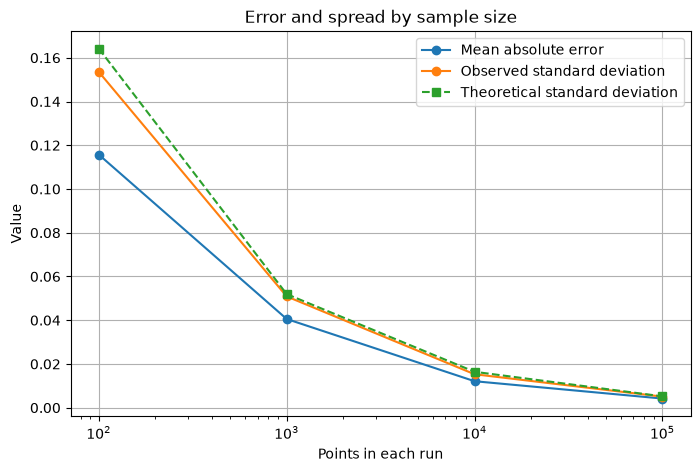

In [29]:
def plot_results(summary, theoretical_spreads):
    point_counts = sorted(summary)
    errors = [summary[n]["mean_absolute_error"] for n in point_counts]
    observed_spreads = [summary[n]["standard_deviation"] for n in point_counts]
    expected_spreads = [theoretical_spreads[n] for n in point_counts]

    plt.figure(figsize=(8, 5))
    plt.plot(point_counts, errors, marker="o", label="Mean absolute error")
    plt.plot(point_counts, observed_spreads, marker="o", label="Observed standard deviation")
    plt.plot(point_counts, expected_spreads, marker="s", linestyle="--",
             label="Theoretical standard deviation")
    plt.xscale("log")
    plt.xlabel("Points in each run")
    plt.ylabel("Value")
    plt.title("Error and spread by sample size")
    plt.legend()
    plt.grid(True)
    plt.show()


plot_results(summary, theoretical_spreads)

## Comparing with the midpoint rule

We can also write π as the area under a curve:

$$\pi=\int_0^1 4\sqrt{1-x^2}\,dx.$$

The midpoint rule splits the interval from 0 to 1 into equal parts. It checks the curve at the middle of each part and uses those heights to estimate the area. This gives us a second way to estimate π.

In [30]:
def estimate_pi_midpoint(n_intervals):
    midpoints = (np.arange(n_intervals) + 0.5) / n_intervals
    heights = np.sqrt(1 - midpoints ** 2)
    estimate = 4 * np.mean(heights)
    return estimate


def compare_methods(point_counts, summary):
    comparison = {}

    for n_points in point_counts:
        monte_carlo_error = summary[n_points]["mean_absolute_error"]
        midpoint_estimate = estimate_pi_midpoint(n_points)
        midpoint_error = abs(midpoint_estimate - np.pi)

        comparison[n_points] = {
            "monte_carlo_error": monte_carlo_error,
            "midpoint_error": midpoint_error
        }

    return comparison

In [31]:
method_comparison = compare_methods(point_counts, summary)

for n_points in point_counts:
    values = method_comparison[n_points]
    print("Points or intervals:", n_points)
    print("Monte Carlo mean absolute error:", values["monte_carlo_error"])
    print("Midpoint error:", values["midpoint_error"])
    print()

Points or intervals: 100
Monte Carlo mean absolute error: 0.11572036732051036
Midpoint error: 0.00034420431021509046

Points or intervals: 1000
Monte Carlo mean absolute error: 0.04056444078461245
Midpoint error: 1.0891323109607498e-05

Points or intervals: 10000
Monte Carlo mean absolute error: 0.012111632679489653
Midpoint error: 3.4443484553392523e-07

Points or intervals: 100000
Monte Carlo mean absolute error: 0.004188053071795856
Midpoint error: 1.0892052593192147e-08



## What the results show

The mean absolute error and standard deviation usually get smaller as the number of points increases. The observed standard deviations can be compared with the theoretical values from the formula above.

The Monte Carlo estimate changes between runs because it uses random points. The midpoint estimate is the same each time for a given number of intervals. The results show how the two methods behaved in this experiment.

In [32]:
for n_points in (point_counts[0], point_counts[-1]):
    values = summary[n_points]
    print("Points:", n_points)
    print("Mean estimate:", values["mean_estimate"])
    print("Mean absolute error:", values["mean_absolute_error"])
    print("Observed standard deviation:", values["standard_deviation"])
    print("Theoretical standard deviation:", theoretical_spreads[n_points])
    print()

Points: 100
Mean estimate: 3.149599999999999
Mean absolute error: 0.11572036732051036
Observed standard deviation: 0.15355041075560846
Theoretical standard deviation: 0.1642183367736324

Points: 100000
Mean estimate: 3.1414134000000002
Mean absolute error: 0.004188053071795856
Observed standard deviation: 0.005066446173021141
Theoretical standard deviation: 0.005193039777692652



## Scope and limitations

This is a small geometry example of Monte Carlo estimation. The same idea can be used to estimate areas or probabilities when an exact answer is hard to find. Here, we already know π, so we can check how close our estimates are.

The results depend on the random points and the seeds used. We ran 200 trials at each point count, but a different set of trials could give slightly different results.

The Monte Carlo method needs more points to reduce its error. In general, cutting the expected spread about in half takes around four times as many points. The midpoint rule does not use random points, but the comparison here only covers this one curve.

## Conclusion and self-assessment

In these runs, larger samples gave estimates closer to π on average and reduced the spread between results. The observed standard deviations can be compared with the values predicted by the probability model. This illustrates the Law of Large Numbers and the expected $1/\sqrt{N}$ pattern.

The midpoint rule gave us a second way to estimate π. The comparison shows how the two methods behaved for this example, but it does not prove that one method is always better.

The project uses the geometric idea, explains the math, runs four point counts over 200 trials each, and compares two methods. A limitation is that π is already known and only one example is studied. A next step could be to estimate an area or probability that is harder to calculate exactly.